# Taller · Una recta no se dobla

El viernes Daniela prometió 14.420 unidades al comité de Bebidas Cumbre usando el plano de TV y radio. Hoy revisas esa cifra, le enseñas al modelo a doblarse y aprendes a frenarlo cuando se dobla de más. Este cuaderno sigue las seis etapas de la página de D2L. No necesitas escribir Python: pídele cada celda a Claude, Gemini o Antigravity. Lo que se califica es que sepas qué te dio y lo hayas verificado.

> **Hoy haces** · Encuentras dónde falla el plano, agregas curvas e interacciones, corriges la promesa, contestas la oferta de la agencia y pruebas Ridge y Lasso.
>
> **Entrega** · Enlace público de este cuaderno con todo ejecutado, memo de una página y `prompts.md`.
>
> **Antes de empezar** · En Colab, arrastra `mercados-bebidas-cumbre.csv` y `consumo-combustible-co2.csv` al panel de archivos de la izquierda.

In [1]:
# --- Setup ---
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error as mae, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

df = pd.read_csv("mercados-bebidas-cumbre.csv")
MARGEN = 12  # USD de margen por unidad. Ventas en miles de unidades, inversión en miles de USD.

# Train y test: siempre la misma división, la del caso anterior
tr, te = train_test_split(df, test_size=0.25, random_state=42)
MEDIOS = ["tv", "radio", "prensa"]
print(df.shape, tr.shape, te.shape)

(200, 5) (150, 5) (50, 5)


## Etapa 1 · Dónde falla el plano

Ajusta el plano `ventas ~ tv + radio` con los 200 mercados. Calcula el error de cada mercado (real menos pronóstico), dibújalo en un gráfico de TV contra radio y promedia los mercados con `tv <= 90` y `radio >= 35`.

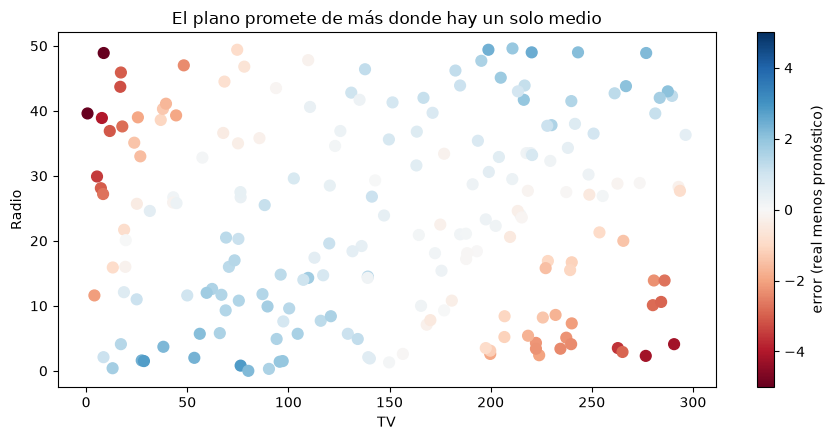

20 10.160000000000002 12.43023027436717 -2.270230274367171


In [2]:
plano = smf.ols("ventas ~ tv + radio", df).fit()
df["error_plano"] = plano.resid
plt.figure(figsize=(9, 4.5))
plt.scatter(df.tv, df.radio, c=df.error_plano, cmap="RdBu", vmin=-5, vmax=5, s=60)
plt.colorbar(label="error (real menos pronóstico)")
plt.xlabel("TV"); plt.ylabel("Radio")
plt.title("El plano promete de más donde hay un solo medio")
plt.tight_layout(); plt.show()
vecinos = df[(df.tv <= 90) & (df.radio >= 35)]
print(len(vecinos), vecinos.ventas.mean(), plano.fittedvalues[vecinos.index].mean(), vecinos.error_plano.mean())
assert abs(vecinos.error_plano.mean() - (-2.270230274367171)) < 1e-6

**Decisión para el memo.** ¿El error del plano es ruido o patrón? Si es patrón, ¿en qué tipo de mercado promete de más?

## Etapa 2 · Doblar el plano

Agrega `tv × radio` y después `tv²`. Mide cada modelo con los 50 mercados de prueba y compáralo con la línea base.

In [3]:
def medir(modelo, cols, nombre):
    modelo.fit(tr[cols], tr.ventas)
    err = mae(te.ventas, modelo.predict(te[cols]))
    print(f"{nombre:28s} error prueba {err:.3f}")
    return err

tr, te = tr.copy(), te.copy()
for parte in (tr, te):
    parte["tv_radio"] = parte.tv * parte.radio
    parte["tv2"] = parte.tv ** 2

base = medir(DummyRegressor(), ["tv"], "promedio")
pl = medir(LinearRegression(), ["tv", "radio"], "tv + radio")
it = medir(LinearRegression(), ["tv", "radio", "tv_radio"], "con interacción")
cu = medir(LinearRegression(), ["tv", "radio", "tv_radio", "tv2"], "con interacción y curva")
assert abs(cu - (0.48328913175944677)) < 1e-6 and abs(pl - (1.3886802126434379)) < 1e-6

promedio                     error prueba 4.678
tv + radio                   error prueba 1.389
con interacción              error prueba 0.650
con interacción y curva      error prueba 0.483


**Decisión para el memo.** ¿Cuál de las dos columnas aportó más? ¿Por qué tiene sentido de negocio?

## Etapa 3 · Corregir la promesa

Ajusta el modelo de cuatro columnas con los 200 mercados. Pronostica los dos planes y calcula la utilidad: unidades por margen menos inversión. Luego calcula cuánto rinde la radio cuando la TV vale 50, 150 y 250.

In [4]:
curva = smf.ols("ventas ~ tv + radio + tv:radio + I(tv**2)", df).fit()
planes = pd.DataFrame({"tv": [150, 50], "radio": [25, 49]}, index=["agencia", "daniela"])
planes["ventas"] = curva.predict(planes)
planes["utilidad"] = planes.ventas * MARGEN - planes.tv - planes.radio
print(planes.round(2))
b = curva.params
for t in (50, 150, 250):
    u = (b["radio"] + b["tv:radio"] * t) * 1000
    print(f"TV {t}: {u:.0f} unidades por mil USD en radio, ganancia {u * MARGEN - 1000:,.0f} USD")
assert abs(planes.loc["daniela", "ventas"] - (11.769358744040487)) < 1e-6

          tv  radio  ventas  utilidad
agencia  150     25   15.22      7.67
daniela   50     49   11.77     42.23
TV 50: 89 unidades por mil USD en radio, ganancia 68 USD
TV 150: 197 unidades por mil USD en radio, ganancia 1,360 USD
TV 250: 304 unidades por mil USD en radio, ganancia 2,652 USD


**Decisión para el memo.** ¿Cambia la decisión de lanzar con el plan de Daniela? ¿Qué cifra le dices al comité y cómo explicas que bajó?

## Etapa 4 · La oferta de la agencia

Ajusta polinomios de grado 1 a 7 con los tres medios y mira el R² de entrenamiento junto al error de prueba.

In [5]:
filas = []
for d in range(1, 8):
    p = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    p.fit(tr[MEDIOS], tr.ventas)
    filas.append({"grado": d, "columnas": p[0].n_output_features_, "r2_entrenamiento": p.score(tr[MEDIOS], tr.ventas),
                  "error_entrenamiento": mae(tr.ventas, p.predict(tr[MEDIOS])), "error_prueba": mae(te.ventas, p.predict(te[MEDIOS]))})
tabla = pd.DataFrame(filas)
print(tabla.round(3).to_string(index=False))
assert abs(tabla.loc[5, "error_prueba"] - (3.253500610147634)) < 1e-4

 grado  columnas  r2_entrenamiento  error_entrenamiento  error_prueba
     1         3             0.897                1.216         1.402
     2         9             0.986                0.413         0.514
     3        19             0.992                0.326         0.354
     4        34             0.995                0.276         0.464
     5        55             0.998                0.191         1.702
     6        83             0.998                0.148         3.254
     7       119             0.999                0.094        42.893


**Decisión para el memo.** ¿Compran el modelo de la agencia? Respondan con el número que un comité entendería.

## Etapa 5 · El freno

Grado 5 con los tres medios. Elige α con validación cruzada dentro de los 150 de entrenamiento. Recién después abre los 50 de prueba.

In [6]:
kf = KFold(5, shuffle=True, random_state=42)
ALPHAS_LASSO = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
ALPHAS_RIDGE = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]

def freno(modelo):
    return make_pipeline(PolynomialFeatures(5, include_bias=False), StandardScaler(), modelo)

def rejilla(alphas, crear):
    filas = []
    for a in alphas:
        p = freno(crear(a))
        cv = -cross_val_score(p, tr[MEDIOS], tr.ventas, cv=kf, scoring="neg_mean_absolute_error").mean()
        p.fit(tr[MEDIOS], tr.ventas)
        filas.append({"alpha": a, "error_validacion": cv, "columnas_vivas": int((abs(p[-1].coef_) > 1e-9).sum()), "error_prueba": mae(te.ventas, p.predict(te[MEDIOS]))})
    return pd.DataFrame(filas)

la = rejilla(ALPHAS_LASSO, lambda a: Lasso(alpha=a, max_iter=300000))
ri = rejilla(ALPHAS_RIDGE, lambda a: Ridge(alpha=a))
print(la.round(3).to_string(index=False)); print(); print(ri.round(3).to_string(index=False))
mejor = la.loc[la.error_validacion.idxmin()]
print("mejor Lasso", mejor.to_dict())
assert mejor.alpha == 0.003 and int(mejor.columnas_vivas) == 16

 alpha  error_validacion  columnas_vivas  error_prueba
 0.000             0.438              37         0.483
 0.000             0.401              33         0.332
 0.001             0.392              23         0.316
 0.003             0.387              16         0.348
 0.010             0.408              11         0.433
 0.030             0.471               8         0.522
 0.100             0.567               6         0.553
 0.300             0.713               2         0.613
 1.000             1.053               2         1.046

 alpha  error_validacion  columnas_vivas  error_prueba
  0.01             0.428              55         0.383
  0.03             0.420              55         0.365
  0.10             0.424              55         0.411
  0.30             0.429              55         0.443
  1.00             0.458              55         0.525
  3.00             0.528              55         0.607
 10.00             0.623              55         0.653
 30.00   

**Decisión para el memo.** ¿Con cuál se queda Daniela: la curva de cuatro columnas o el Lasso? Argumenten con error y con lo que se puede explicar.

## Etapa 6 · En casa

Primero propón una columna con sentido de negocio y gánale al modelo de cuatro columnas en los mismos 50 mercados. Luego abre el dataset de CO₂ de años anteriores y mira qué le pasa a un coeficiente cuando las columnas son casi copias.

In [7]:
for parte in (tr, te):
    parte["raiz_tv"] = np.sqrt(parte.tv)
r4 = medir(LinearRegression(), ["tv", "raiz_tv", "radio", "tv_radio"], "tv, raíz de tv, radio, tv × radio")
assert abs(r4 - (0.28718461239483767)) < 1e-6

tv, raíz de tv, radio, tv × radio error prueba 0.287


In [8]:
co2 = pd.read_csv("consumo-combustible-co2.csv")
COLS = ["ENGINESIZE", "CYLINDERS", "FUELCONSUMPTION_CITY", "FUELCONSUMPTION_HWY", "FUELCONSUMPTION_COMB", "FUELCONSUMPTION_COMB_MPG"]
print(co2[COLS].corr().round(3))
filas = []
for seed in range(6):
    mitad = co2.sample(frac=0.5, random_state=seed)
    for n, m in (("sin freno", LinearRegression()), ("ridge", Ridge(alpha=50)), ("lasso", Lasso(alpha=1, max_iter=300000))):
        p = make_pipeline(StandardScaler(), m).fit(mitad[COLS], mitad.CO2EMISSIONS)
        filas.append({"seed": seed, "modelo": n, "coef_comb": p[-1].coef_[4]})
res = pd.DataFrame(filas).pivot(index="seed", columns="modelo", values="coef_comb")
print(res.round(1))
assert abs(res["sin freno"].min() - (-86.55532773300287)) < 1e-4 and abs(res["sin freno"].max() - (197.58242848012637)) < 1e-4

                          ENGINESIZE  CYLINDERS  FUELCONSUMPTION_CITY  \
ENGINESIZE                     1.000      0.934                 0.832   
CYLINDERS                      0.934      1.000                 0.796   
FUELCONSUMPTION_CITY           0.832      0.796                 1.000   
FUELCONSUMPTION_HWY            0.779      0.725                 0.966   
FUELCONSUMPTION_COMB           0.819      0.777                 0.996   
FUELCONSUMPTION_COMB_MPG      -0.809     -0.770                -0.936   

                          FUELCONSUMPTION_HWY  FUELCONSUMPTION_COMB  \
ENGINESIZE                              0.779                 0.819   
CYLINDERS                               0.725                 0.777   
FUELCONSUMPTION_CITY                    0.966                 0.996   
FUELCONSUMPTION_HWY                     1.000                 0.986   
FUELCONSUMPTION_COMB                    0.986                 1.000   
FUELCONSUMPTION_COMB_MPG               -0.894                -

**Decisión para el memo.** ¿Cuándo le recomendarías a Daniela Ridge, cuándo Lasso y cuándo ninguno?